In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Select GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu128
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [4]:
import os

DATASET_DIR = r"./dataset/PetImages"

print("Dataset exists:", os.path.exists(DATASET_DIR))
print("Contents:", os.listdir(DATASET_DIR))
    

Dataset exists: True
Contents: ['Cat', 'Dog']


In [5]:
class CatDogDataset(Dataset):
    def __init__(self, root_dir, image_size=128):
        self.root_dir = root_dir
        self.image_size = image_size
        self.samples = []

        class_names = ["Cat", "Dog"]

        for label, class_name in enumerate(class_names):
            class_dir = os.path.join(root_dir, class_name)

            for filename in os.listdir(class_dir):
                filepath = os.path.join(class_dir, filename)

                if filename.lower().endswith((".jpg", ".jpeg", ".png")):
                    self.samples.append((filepath, label))

        self.class_names = class_names

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        filepath, label = self.samples[index]

        image = Image.open(filepath).convert("RGB")
        image = image.resize((self.image_size, self.image_size))

        image = np.array(image, dtype=np.float32)
        image = image / 255.0

        # H x W x C → C x H x W
        image = np.transpose(image, (2, 0, 1))

        image = torch.tensor(image, dtype=torch.float32)
        label = torch.tensor(label, dtype=torch.float32)

        return image, label


dataset = CatDogDataset(DATASET_DIR)

print("Total images:", len(dataset))
print("Classes:", dataset.class_names)

Total images: 24998
Classes: ['Cat', 'Dog']


Image shape: torch.Size([3, 128, 128])
Label: 0
Class: Cat


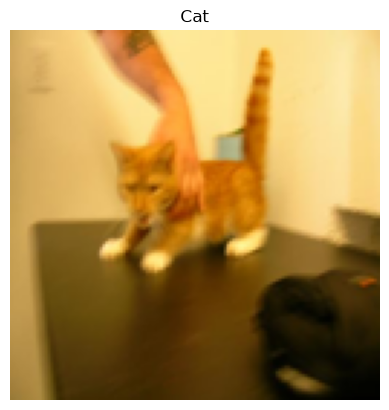

In [6]:
image, label = dataset[0]

print("Image shape:", image.shape)
print("Label:", int(label))
print("Class:", dataset.class_names[int(label)])

plt.imshow(image.permute(1, 2, 0))
plt.title(dataset.class_names[int(label)])
plt.axis("off")
plt.show()

In [7]:
from torch.utils.data import random_split

# 80% training, 20% validation
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=generator
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Training images: 19998
Validation images: 5000


In [8]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 625
Validation batches: 157


In [9]:
class CatDogCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # 128 x 128
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 64 x 64
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 32 x 32
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 16 x 16
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
            
            # Output: 256 x 8 x 8
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),

            nn.Linear(256 * 8 * 8, 256),
            nn.ReLU(),

            nn.Dropout(0.5),

            nn.Linear(256, 1)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x.squeeze(1)


model = CatDogCNN().to(device)

print(model)

CatDogCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=16384, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=1, bias=True)
  )
)


In [11]:
class ManualAdam:
    def __init__(self, parameters, lr=0.001, betas=(0.9, 0.999), eps=1e-8):
        self.parameters = list(parameters)
        self.lr = lr
        self.beta1, self.beta2 = betas
        self.eps = eps

        self.m = [torch.zeros_like(p) for p in self.parameters]
        self.v = [torch.zeros_like(p) for p in self.parameters]
        self.step_count = 0

    @torch.no_grad()
    def step(self):
        self.step_count += 1

        for i, param in enumerate(self.parameters):
            if param.grad is None:
                continue

            grad = param.grad

            # First moment
            self.m[i].mul_(self.beta1)
            self.m[i].add_(grad, alpha=1 - self.beta1)

            # Second moment
            self.v[i].mul_(self.beta2)
            self.v[i].addcmul_(grad, grad, value=1 - self.beta2)

            # Bias correction
            m_hat = self.m[i] / (1 - self.beta1 ** self.step_count)
            v_hat = self.v[i] / (1 - self.beta2 ** self.step_count)

            # Adam update
            param.addcdiv_(
                m_hat,
                torch.sqrt(v_hat) + self.eps,
                value=-self.lr
            )

    @torch.no_grad()
    def zero_grad(self):
        for param in self.parameters:
            if param.grad is not None:
                param.grad.zero_()


optimizer = ManualAdam(
    model.parameters(),
    lr=0.001
)

print("Manual Adam optimizer created successfully.")
print("Model device:", next(model.parameters()).device)

Manual Adam optimizer created successfully.
Model device: cuda:0


In [12]:
images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

optimizer.zero_grad()

outputs = model(images)

loss = criterion(outputs, labels)

loss.backward()

optimizer.step()

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Loss:", loss.item())
print("GPU:", images.device)

Input shape: torch.Size([32, 3, 128, 128])
Output shape: torch.Size([32])
Loss: 0.6871100664138794
GPU: cuda:0


In [13]:
EPOCHS = 10

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

for epoch in range(EPOCHS):

    # -------------------------
    # Training
    # -------------------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        running_loss += loss.item() * images.size(0)

        predictions = (torch.sigmoid(outputs) >= 0.5).float()

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = correct / total

    # -------------------------
    # Validation
    # -------------------------
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = (torch.sigmoid(outputs) >= 0.5).float()

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_loss = running_loss / total
    val_accuracy = correct / total

    # Store history
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy * 100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy * 100:.2f}%"
    )

C:\Users\Acer\Desktop\Azeez Archieve\STUDY MATERIAL\SEMESTER 5\OCC - MLOps\Binary-classifier-hosting\cat-dog-classifier\.venv\Lib\site-packages\PIL\TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Epoch [1/10] Train Loss: 0.6526 | Train Acc: 61.01% | Val Loss: 0.5825 | Val Acc: 69.44%
Epoch [2/10] Train Loss: 0.5299 | Train Acc: 73.43% | Val Loss: 0.4540 | Val Acc: 78.52%
Epoch [3/10] Train Loss: 0.4379 | Train Acc: 79.38% | Val Loss: 0.4154 | Val Acc: 81.34%
Epoch [4/10] Train Loss: 0.3735 | Train Acc: 83.39% | Val Loss: 0.3657 | Val Acc: 83.46%
Epoch [5/10] Train Loss: 0.3244 | Train Acc: 85.95% | Val Loss: 0.3589 | Val Acc: 83.32%
Epoch [6/10] Train Loss: 0.2757 | Train Acc: 88.25% | Val Loss: 0.2881 | Val Acc: 87.34%
Epoch [7/10] Train Loss: 0.2342 | Train Acc: 90.16% | Val Loss: 0.3220 | Val Acc: 86.46%
Epoch [8/10] Train Loss: 0.1943 | Train Acc: 92.17% | Val Loss: 0.2863 | Val Acc: 88.18%
Epoch [9/10] Train Loss: 0.1600 | Train Acc: 93.48% | Val Loss: 0.2925 | Val Acc: 87.98%
Epoch [10/10] Train Loss: 0.1258 | Train Acc: 94.98% | Val Loss: 0.3116 | Val Acc: 87.90%


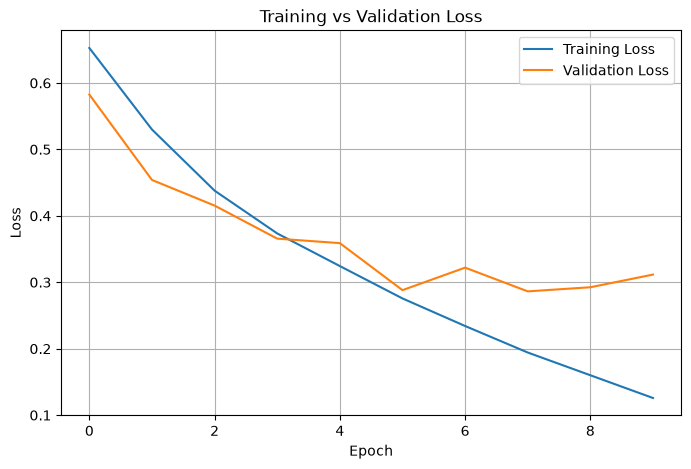

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

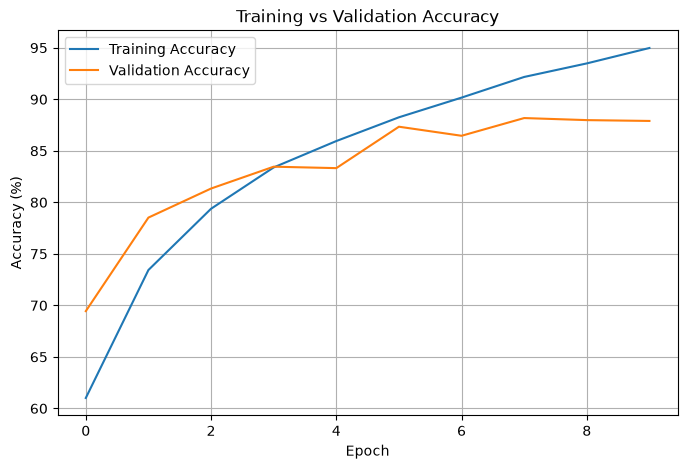

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(
    [x * 100 for x in train_accuracies],
    label="Training Accuracy"
)

plt.plot(
    [x * 100 for x in val_accuracies],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()